# Plot Venn Diagrams between 2 experiments

Experiments
* Handpicked 37 jets (Guo et al. 2022)
* Fontanka (Galitsyna et al., 2023) 
* Fun (Liu et al., 2024) 
* MIA-Jet 

In [1]:
import sys
sys.path.append('..')
from utils.plotting import plot_n_hic, genomic_labels
from notebooks.func_analysis import *
from notebooks.func_plotting import *
from notebooks.func_iou import *
from notebooks.func_pileup import *

import os
import pandas as pd
import itertools
from matplotlib_venn import venn2
import matplotlib.pyplot as plt
import bioframe as bf
import numpy as np

In [2]:
def safe_int(x):
    try:
        return int(x)
    except ValueError:
        return x

# DP thymocytes (mm9)

The reason why we separate DP thymocyte and other cell lines is because 
1. Guo et al. has manual annotations which we consider as another "jet caller" 
2. DP thymocytes has ChIP-seq tracks which we wish to plot also

In [3]:
# Should be the resolution of the miajet program
# This should be standardized across all methods
# This parameter is used to define the sampling frequency of the jet lines 
resolution = 50000 # 50Kb resolution

hic_file = "/nfs/turbo/umms-minjilab/downloaded_data/GSE199059_CD69negDPWTR1R2R3R4_merged.hic"
data_name = "GSE199059_CD69negDPWTR1R2R3R4_merged"

# FUN
f_pred_fun_bedpe = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/other_methods/FUN_{data_name}_{resolution // 1e3:.0f}kb/FUN-pred_{resolution}_1.3.bedpe"
f_pred_fun_tab = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/other_methods/FUN_{data_name}_{resolution // 1e3:.0f}kb/FUN-pred_{resolution}_1.3.tab"


# # FONTANKA
# Only 50 kb exists for now with ws-small
f_pred_fontanka = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/other_methods/FONTANKA_ws-small_{data_name}_{resolution // 1e3:.0f}kb.{resolution}.predicted.fountains.thresholded.tsv"


# MIA-JET
output_name = "v2.0.3"
result_type = "q_val_0.15-0.15" # 50 bkb (OK)
hic_name = os.path.basename(hic_file).split(".hic")[0]
resolution_miajet = resolution
f_pred_miajet_summary = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/miajet/output_{output_name}/{hic_name}_chr_combined_{genomic_labels(resolution_miajet)}/{hic_name}_chr_combined_{result_type}_{genomic_labels(resolution_miajet)}_summary_table.csv"
f_pred_miajet_expanded = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/miajet/output_{output_name}/{hic_name}_chr_combined_{genomic_labels(resolution_miajet)}/{hic_name}_chr_combined_{result_type}_{genomic_labels(resolution_miajet)}_expanded_table.csv"


# HAND-PICKED (Guo et al. 2022 DP thymocytes ONLY)
f_guo37 = "/nfs/turbo/umms-minjilab/sionkim/jet_pred/GUO-37_mm9.tsv"

# AUXILIAR DATA (ChIP-seq)
chip_files = [
    "/nfs/turbo/umms-minjilab/downloaded_data/dp_thymocytes_input-R1_chipseq_Guo-2022_GSM5963432_mm9.bedGraph",
    "/nfs/turbo/umms-minjilab/downloaded_data/dp_thymocytes_H3K27ac-R1_chipseq_Guo-2022_GSM5963434_mm9.bedGraph",
    "/nfs/turbo/umms-minjilab/downloaded_data/dp_thymocytes_RAD21-R1_chipseq_Guo-2022_GSM5963436_mm9.bedGraph",
    "/nfs/turbo/umms-minjilab/downloaded_data/dp_thymocytes_CTCF_chipseq_Guo-2022_GSM5963438_mm9.bedGraph",
    "/nfs/turbo/umms-minjilab/processing/results/SRR931714/dp_thymocytes_NIPBL_SRR931714_miseq.q30.nr.sorted.bedgraph",
]

chip_names = [
    "ChIP-seq input control GSM5963432 (R1)",
    "ChIP-seq H3K27ac GSM5963434 (R1)",
    "ChIP-seq RAD21 GSM5963436 (R1)",
    "ChIP-seq CTCF GSM5963438",
    "ChIP-seq NIPBL SRR931714 (R2)",
]

chip_names_abrev = ["Input", "H3K27ac", "RAD21", "CTCF", "NIPBL"]

genome = "mm9"
f_chrom_sizes = "/nfs/turbo/umms-minjilab/processing/genomes/mm9/mm9.chrom.sizes"

# Common parameters
save_path = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/revision2"


# Pileup parameters
expected_stack_size = 100
data_type = "oe"
normalization = "VC_SQRT"

In [4]:
guo37_table = pd.read_csv(f_guo37, sep="\t")

In [5]:
# Load it in
fun_bedpe = pd.read_csv(f_pred_fun_bedpe, sep="\t")
fun_table = pd.read_csv(f_pred_fun_tab, sep="\t")

fontanka_table = pd.read_csv(f_pred_fontanka, sep="\t", index_col=0)
fontanka_table.dropna(inplace=True, how="any")
fontanka_table.reset_index(inplace=True, drop=True)

miajet_positions = pd.read_csv(f_pred_miajet_expanded, comment="#")
miajet_table = pd.read_csv(f_pred_miajet_summary, comment="#")

# 3 NEW MODIFICATIONS
miajet_table['length'] = miajet_table['length'] * resolution_miajet

# Common chromosome determination
# Lets not include Guo et al. because they didn't find any in chrX
# For a fair comparison of overlaps, we will only consider the common chromosomes

chromsizes = bf.fetch_chromsizes(db=genome, as_bed=True)
common_chroms = chromsizes["chrom"].tolist()
common_chroms.remove("chrM")  # remove chrM if present
common_chroms.remove('chrY')

miajet_table = miajet_table[miajet_table["chrom"].isin(common_chroms)]
fun_table = fun_table[fun_table["chrom"].isin(common_chroms)]
fontanka_table = fontanka_table[fontanka_table["chrom"].isin(common_chroms)]

print(f"Common chromosomes: {common_chroms}")

Common chromosomes: ['chr1', 'chr2', 'chr3', 'chr4', 'chr5', 'chr6', 'chr7', 'chr8', 'chr9', 'chr10', 'chr11', 'chr12', 'chr13', 'chr14', 'chr15', 'chr16', 'chr17', 'chr18', 'chr19', 'chrX']


## Preprocessing

In [6]:
# midpoint
fun_bedpe["extrusion_x"] = (fun_bedpe["y1"] + fun_bedpe["y2"]) / 2
fun_bedpe["extrusion_y"] = (fun_bedpe["x1"] + fun_bedpe["x2"]) / 2

# guarantees that the extrusion point is in the upper diagonal
# doesn't matter except for convention but should be standardized for all points
assert np.all(fun_bedpe["extrusion_x"] >= fun_bedpe["extrusion_y"])

# the main table hosts the "start" and "end" positions, which is the main diagonal start and end
# to get a single point for the jet, we can use the midpoint of the start and end positions
fun_table["root"] = (fun_table["start"] + fun_table["end"]) / 2
# Note that "root" position should technically be "root_x" and "root_y" but since 
# this is a point on the main diagonal, they are the same and we can just use one value

# Lets add a unique identifier now
fun_table["unique_id"] = fun_table.index

# Lets combine them
fun_minimal = fun_bedpe.copy()

fun_minimal["root"] = fun_table["root"]

# Lets add a unique identifier now
fun_minimal["unique_id"] = fun_minimal.index
fun_minimal["chrom"] = fun_table["chrom"]

fun_minimal = fun_minimal[["unique_id", "chrom", "root", "extrusion_x", "extrusion_y"]]

fun_positions = generate_positions(fun_minimal, resolution)
fun_positions["unique_id"] = fun_positions["unique_id"].astype(int)

In [7]:
fontanka_table = fontanka_table.reset_index(drop=True)
fontanka_table["root"] = (fontanka_table["end"] + fontanka_table["start"]) / 2
fontanka_table["unique_id"] = fontanka_table.index
fontanka_table["extrusion_x"] = fontanka_table["window_end"]
fontanka_table["extrusion_y"] = fontanka_table["window_start"]

# guarantees that the extrusion point is in the upper diagonal
# doesn't matter except for convention but should be standardized for all points
assert np.all(fontanka_table["extrusion_x"] >= fontanka_table["extrusion_y"])

fontanka_minimal = fontanka_table.copy()

fontanka_minimal = fontanka_minimal[["unique_id", "chrom", "root", "extrusion_x", "extrusion_y"]]

fontanka_positions = generate_positions(fontanka_minimal, resolution)
fontanka_positions["unique_id"] = fontanka_positions["unique_id"].astype(int)

In [8]:
guo37_table = guo37_table.reset_index(drop=True)

guo37_table["extrusion_x"] = (guo37_table["Pos_kb"] + guo37_table["WT_d2_kb"]) * 1000
guo37_table["extrusion_y"] = (guo37_table["Pos_kb"] - guo37_table["WT_d1_kb"]) * 1000

assert np.all(guo37_table["extrusion_x"] >= guo37_table["extrusion_y"])

guo37_table["root"] = guo37_table["Pos_kb"] * 1000

guo37_table["chrom"] = "chr" + guo37_table["Chr"].astype(str)

guo37_table["unique_id"] = guo37_table.index

guo37_table["start"] = (guo37_table["Pos_kb"] - 1) * 1000
guo37_table["end"] = (guo37_table["Pos_kb"] + 1) * 1000

guo37_minimal = guo37_table.copy()
guo37_minimal = guo37_minimal[["unique_id", "chrom", "root", "extrusion_x", "extrusion_y"]]
guo37_positions = generate_positions(guo37_minimal, resolution)

In [9]:
ranking_col = [
    "sum_consistency", # changed! 
    "SoN", 
    "FS_peaks", 
    "Strength_au_WT"
]

# Expanded
positions = [
    miajet_positions,
    fun_positions,
    fontanka_positions, 
    guo37_positions
]

# Summary
tables = [
    miajet_table,
    fun_table,
    fontanka_table,
    guo37_table
]

names = [
    f"MIA-Jet {result_type}",
    "Fun",
    "Fontanka",
    "Guo et al. 2022"
]

palette = {
    f"MIA-Jet {result_type}" : "#00bfff",
    "Fun" : "#ffbf00",
    "Fontanka" : "#d22b2b",
    "Guo et al. 2022" : "#808080",
}

In [10]:
position_dict = dict(zip(names, positions))
table_dict = dict(zip(names, tables))

In [11]:
result_type += f" {ranking_col[0]}"

In [12]:
chrom_sizes = bf.fetch_chromsizes(genome, as_bed=True)

In [13]:
chrom_sizes = chrom_sizes.loc[~chrom_sizes['chrom'].isin(['chrY', 'chrM'])]

## ALL Aggregate plots

In [14]:
# Regenerate the start and end positions for the aggregation 
bed_tables = []
for i, (s, e) in enumerate(zip(tables, positions)):
    bed_tables.append(generate_bed_2(s, e, eps=500e3, fraction=1.5))

In [15]:
agg_map = []
vmaxes = []
df_stack = []

for bed_df in bed_tables:
    # Get pileups for each bed_df
    s, d, r = get_pileups_dynamic_resolution(
        hic_file=hic_file,
        bed_df_in=bed_df,
        expected_stack_size=expected_stack_size,
        chrom_sizes=chrom_sizes,
        chromosomes='all',
        window_range=(None, None),
        data_type=data_type,
        normalization=normalization,
        sort=True,
        verbose=True
    )

    # Remove centromeres and resize square stacks
    s, d = remove_and_resize_square_stacks(s, d, expected_stack_size)

    if data_type == "observed":
        s = np.log10(s + 1) # log transform for visualization

    a = np.mean(s, axis=0)
    vmaxes.append(np.percentile(a, 99))  # store the 99th percentile for color scaling
    agg_map.append(a)  # average over all stacks
    df_stack.append(d)  # store the DataFrame for later use

Retrieving pileups:   3%|▎         | 9/332 [00:00<00:13, 24.45it/s]

Retrieving pileups: 100%|██████████| 37/37 [00:02<00:00, 16.79it/s]


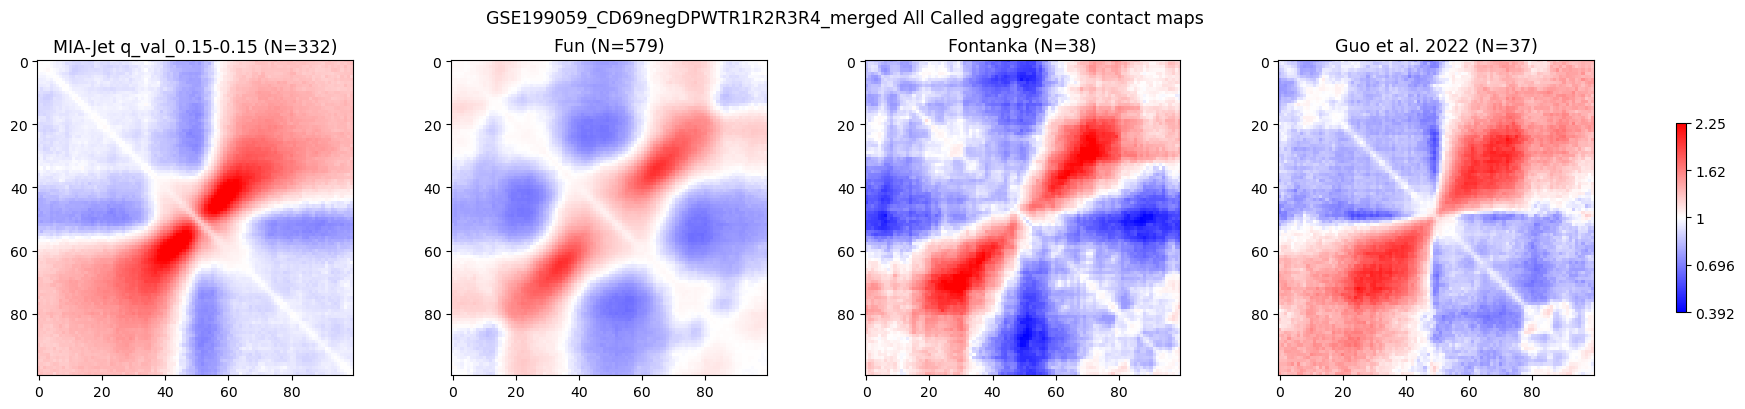

In [16]:
titles = [f"{names[i]} (N={len(df_stack[i])})" for i in range(len(names))]

plot_n_hic(
    agg_map,
    suptitle=f"{data_name} All Called aggregate contact maps",
    resolution=None,
    cmap_label=None,
    titles=titles,
    cmap='bwr',
    vcenter=1,
    standardize_cbar=True,
    show=True, 
    vmax=vmaxes, 
    share_xy=False,
    ppr=4,
    # savepath=f"{save_path}/{data_name}_{resolution_miajet}_{result_type}_all_agg_map-{data_type}.png"
)

In [17]:
# For ChIP-seq we use the loading site locations
bed_tables = []
for i, (s, e) in enumerate(zip(tables, positions)):
    bed_tables.append(generate_bed_3(s, e))

stat = "max"
window_plus_minus = int(50e3) # 50 kb
chipseq_resolution = 10000 # 10kb resolution

intervals = []

for t in bed_tables:
    df_interval = t[["unique_id", "chrom"]].copy()
    df_interval["midpoint"] = (t["start"] + t["end"]) / 2
    df_interval["start"] = df_interval["midpoint"] - window_plus_minus
    df_interval["end"] = df_interval["midpoint"] + window_plus_minus

    intervals.append(df_interval.reset_index(drop=True))

In [18]:
chipseq_values = extract_chipseq_values(chip_files, intervals, f_chrom_sizes, common_chroms, names, stat=stat)

track was not included in <_io.TextIOWrapper name='/nfs/turbo/umms-minjilab/processing/genomes/mm9/mm9.chrom.sizes' mode='r' encoding='UTF-8'>


chr1 is already loaded
chr2 is already loaded
chr3 is already loaded
chr4 is already loaded
chr5 is already loaded
chr6 is already loaded
chr7 is already loaded
chr8 is already loaded
chr9 is already loaded
chr10 is already loaded
chr11 is already loaded
chr12 is already loaded
chr13 is already loaded
chr14 is already loaded
chr15 is already loaded
chr16 is already loaded
chr17 is already loaded
chr18 is already loaded
chr19 is already loaded
chrX is already loaded
chr1 is already loaded
chr2 is already loaded
chr3 is already loaded
chr4 is already loaded
chr5 is already loaded
chr7 is already loaded
chr8 is already loaded
chr9 is already loaded
chr10 is already loaded
chr11 is already loaded
chr13 is already loaded
chr14 is already loaded
chr16 is already loaded
chr17 is already loaded
chr19 is already loaded
chrX is already loaded
chr1 is already loaded
chr2 is already loaded
chr3 is already loaded
chr4 is already loaded
chr5 is already loaded
chr6 is already loaded
chr8 is already l

No jets called for chromosome chr6 by Fontanka
No jets called for chromosome chr12 by Fontanka
No jets called for chromosome chr15 by Fontanka
No jets called for chromosome chr18 by Fontanka
No jets called for chromosome chr7 by Guo et al. 2022
No jets called for chromosome chr15 by Guo et al. 2022
No jets called for chromosome chr18 by Guo et al. 2022
No jets called for chromosome chrX by Guo et al. 2022


chr1 is already loaded
chr2 is already loaded
chr3 is already loaded
chr4 is already loaded
chr5 is already loaded
chr6 is already loaded
chr7 is already loaded
chr8 is already loaded
chr9 is already loaded
chr10 is already loaded
chr11 is already loaded
chr12 is already loaded
chr13 is already loaded
chr14 is already loaded
chr15 is already loaded
chr16 is already loaded
chr17 is already loaded
chr18 is already loaded
chr19 is already loaded
chrX is already loaded
chr1 is already loaded
chr2 is already loaded
chr3 is already loaded
chr4 is already loaded
chr5 is already loaded
chr7 is already loaded
chr8 is already loaded
chr9 is already loaded
chr10 is already loaded
chr11 is already loaded
chr13 is already loaded
chr14 is already loaded
chr16 is already loaded
chr17 is already loaded
chr19 is already loaded
chrX is already loaded
chr1 is already loaded
chr2 is already loaded
chr3 is already loaded
chr4 is already loaded
chr5 is already loaded
chr6 is already loaded
chr8 is already l

No jets called for chromosome chr6 by Fontanka
No jets called for chromosome chr12 by Fontanka
No jets called for chromosome chr15 by Fontanka
No jets called for chromosome chr18 by Fontanka
No jets called for chromosome chr7 by Guo et al. 2022
No jets called for chromosome chr15 by Guo et al. 2022
No jets called for chromosome chr18 by Guo et al. 2022
No jets called for chromosome chrX by Guo et al. 2022


chr1 is already loaded
chr2 is already loaded
chr3 is already loaded
chr4 is already loaded
chr5 is already loaded
chr6 is already loaded
chr7 is already loaded
chr8 is already loaded
chr9 is already loaded
chr10 is already loaded
chr11 is already loaded
chr12 is already loaded
chr13 is already loaded
chr14 is already loaded
chr15 is already loaded
chr16 is already loaded
chr17 is already loaded
chr18 is already loaded
chr19 is already loaded
chrX is already loaded
chr1 is already loaded
chr2 is already loaded
chr3 is already loaded
chr4 is already loaded
chr5 is already loaded
chr7 is already loaded
chr8 is already loaded
chr9 is already loaded
chr10 is already loaded
chr11 is already loaded
chr13 is already loaded
chr14 is already loaded
chr16 is already loaded
chr17 is already loaded
chr19 is already loaded
chrX is already loaded
chr1 is already loaded
chr2 is already loaded
chr3 is already loaded
chr4 is already loaded
chr5 is already loaded
chr6 is already loaded
chr8 is already l

No jets called for chromosome chr6 by Fontanka
No jets called for chromosome chr12 by Fontanka
No jets called for chromosome chr15 by Fontanka
No jets called for chromosome chr18 by Fontanka
No jets called for chromosome chr7 by Guo et al. 2022
No jets called for chromosome chr15 by Guo et al. 2022
No jets called for chromosome chr18 by Guo et al. 2022
No jets called for chromosome chrX by Guo et al. 2022


chr1 is already loaded
chr2 is already loaded
chr3 is already loaded
chr4 is already loaded
chr5 is already loaded
chr6 is already loaded
chr7 is already loaded
chr8 is already loaded
chr9 is already loaded
chr10 is already loaded
chr11 is already loaded
chr12 is already loaded
chr13 is already loaded
chr14 is already loaded
chr15 is already loaded
chr16 is already loaded
chr17 is already loaded
chr18 is already loaded
chr19 is already loaded
chrX is already loaded
chr1 is already loaded
chr2 is already loaded
chr3 is already loaded
chr4 is already loaded
chr5 is already loaded
chr7 is already loaded
chr8 is already loaded
chr9 is already loaded
chr10 is already loaded
chr11 is already loaded
chr13 is already loaded
chr14 is already loaded
chr16 is already loaded
chr17 is already loaded
chr19 is already loaded
chrX is already loaded
chr1 is already loaded
chr2 is already loaded
chr3 is already loaded
chr4 is already loaded
chr5 is already loaded
chr6 is already loaded
chr8 is already l

No jets called for chromosome chr6 by Fontanka
No jets called for chromosome chr12 by Fontanka
No jets called for chromosome chr15 by Fontanka
No jets called for chromosome chr18 by Fontanka
No jets called for chromosome chr7 by Guo et al. 2022
No jets called for chromosome chr15 by Guo et al. 2022
No jets called for chromosome chr18 by Guo et al. 2022
No jets called for chromosome chrX by Guo et al. 2022


chr1 is already loaded
chr2 is already loaded
chr3 is already loaded
chr4 is already loaded
chr5 is already loaded
chr6 is already loaded
chr7 is already loaded
chr8 is already loaded
chr9 is already loaded
chr10 is already loaded
chr11 is already loaded
chr12 is already loaded
chr13 is already loaded
chr14 is already loaded
chr15 is already loaded
chr16 is already loaded
chr17 is already loaded
chr18 is already loaded
chr19 is already loaded
chrX is already loaded
chr1 is already loaded
chr2 is already loaded
chr3 is already loaded
chr4 is already loaded
chr5 is already loaded
chr7 is already loaded
chr8 is already loaded
chr9 is already loaded
chr10 is already loaded
chr11 is already loaded
chr13 is already loaded
chr14 is already loaded
chr16 is already loaded
chr17 is already loaded
chr19 is already loaded
chrX is already loaded
chr1 is already loaded
chr2 is already loaded
chr3 is already loaded
chr4 is already loaded
chr5 is already loaded
chr6 is already loaded
chr8 is already l

No jets called for chromosome chr6 by Fontanka
No jets called for chromosome chr12 by Fontanka
No jets called for chromosome chr15 by Fontanka
No jets called for chromosome chr18 by Fontanka
No jets called for chromosome chr7 by Guo et al. 2022
No jets called for chromosome chr15 by Guo et al. 2022
No jets called for chromosome chr18 by Guo et al. 2022
No jets called for chromosome chrX by Guo et al. 2022


In [19]:
names_forpaper = ["MIA-Jet", "Fun", "Fontanka", "Guo"]

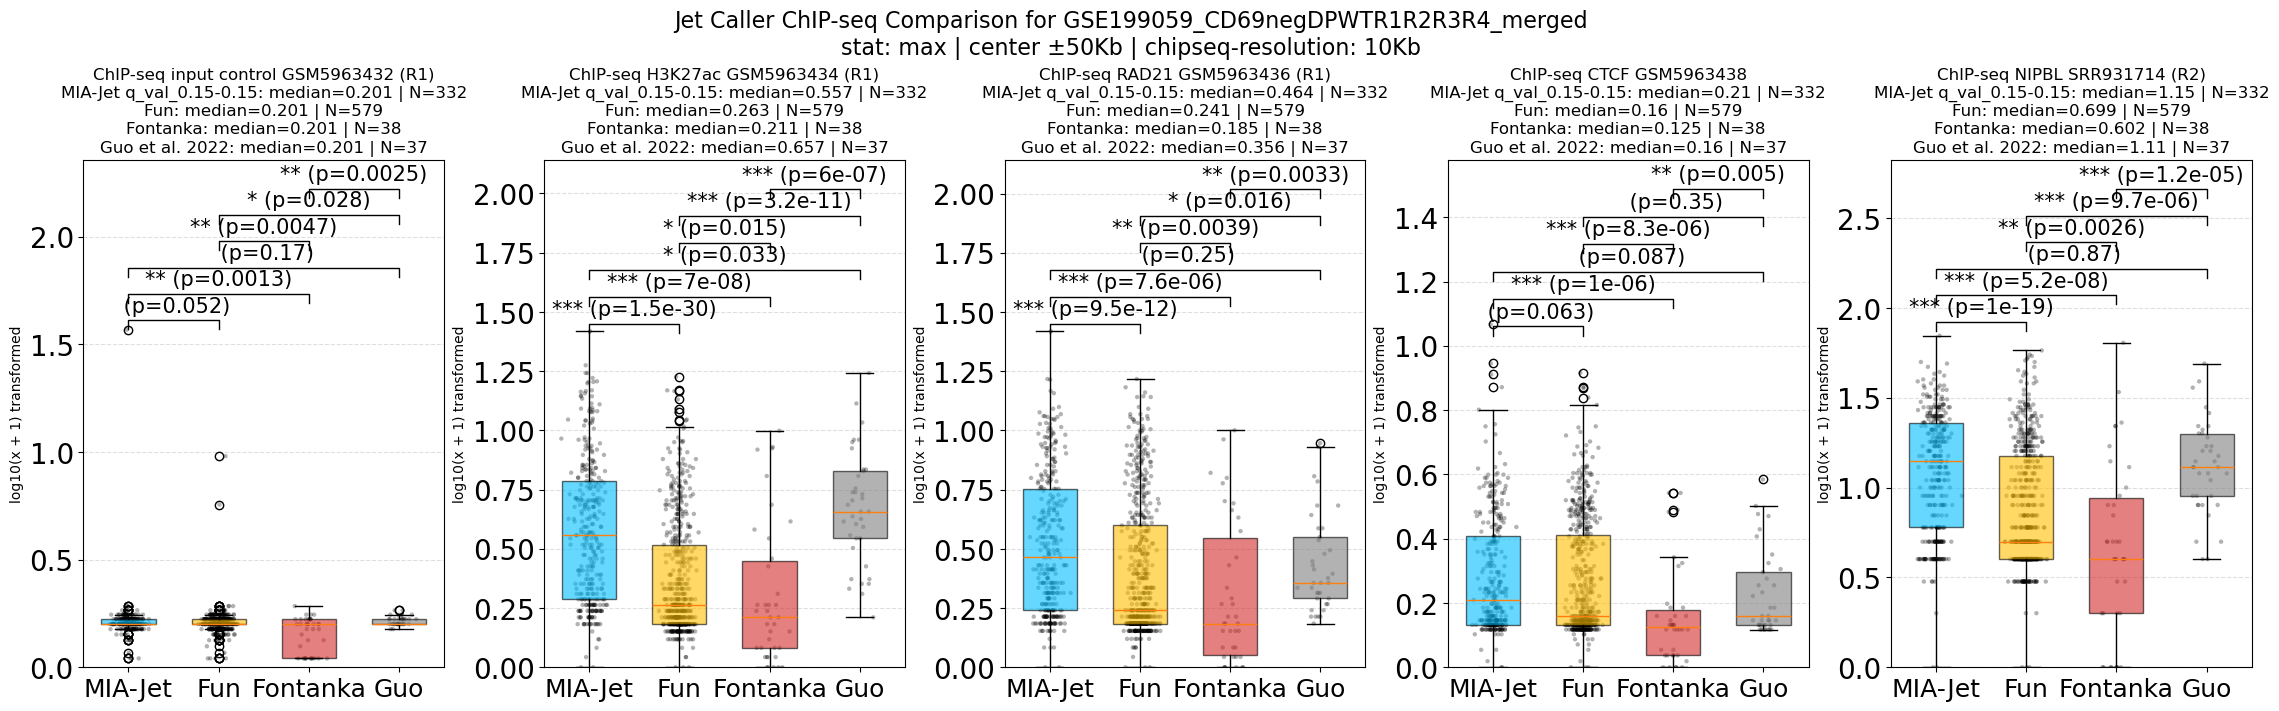

In [20]:
n_exp = len(chip_names)
n_callers = len(names)
colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

fig, ax = plt.subplots(1, n_exp, layout='constrained', figsize=(4.5 * len(chip_names), 7))

for i in range(len(chip_names)):
    chip_name = chip_names_abrev[i]

    datum = chipseq_values[i]
    boxplot_data = [list(x.values()) for x in datum]

    clean_data = [np.array(vals)[~np.isnan(vals)] for vals in boxplot_data]

    # log transform
    clean_data = [np.clip(vals, 0, None) for vals in clean_data]  # clip negative values to zero
    clean_data = [np.log10(vals + 1) for vals in clean_data]
    exp_counts = [len(vals) for vals in clean_data]
    positions_x = np.arange(1, n_callers + 1)

    # make boxplot titles
    title_boxstat = title_boxplot(chip_names[i], names, clean_data)

    # add pairwise significance 
    add_pairwise_sig(ax[i], positions_x, clean_data, fontsize=15, y_pad=0.08, pad_from_max=-0.12)

    bp = ax[i].boxplot(clean_data, patch_artist=True, positions=positions_x, widths=0.6)

    # color each box
    cat_cols = [palette[n] for n in names] 
    for patch, col in zip(bp['boxes'], cat_cols):
        patch.set_facecolor(col)
        patch.set_alpha(0.6)

    # jittered scatter on top
    for j, vals in enumerate(clean_data):
        y = np.array(vals)
        x = np.full_like(y, positions_x[j], dtype=float) + np.random.normal(0, 0.08, size=len(y))
        ax[i].scatter(x, y, alpha=0.3, s=10, color='k', edgecolor='none')

    # x-tick labels
    ax[i].set_xticks(positions_x)
    ax[i].set_xticklabels(names_forpaper, rotation=0, fontsize=18)

    ax[i].set_ylabel("log10(x + 1) transformed")
    
    ax[i].set_title(title_boxstat)
    ax[i].grid(axis='y', linestyle='--', alpha=0.4)

    ax[i].tick_params(axis='y', labelsize=20)

    ax[i].set_ylim(bottom=0, top=ax[i].get_ylim()[1] * 1.01)  # add some space on top for significance annotations


fig.suptitle(f"Jet Caller ChIP-seq Comparison for {data_name}\n"
             f"stat: {stat} | center ±{genomic_labels(window_plus_minus)} | chipseq-resolution: {genomic_labels(chipseq_resolution)}", fontsize=16)

# plt.savefig(f"{save_path}/{data_name}_{resolution_miajet}_{result_type}_chipseq_comparison-all.png", dpi=300)

plt.show()

## Intersection

In [21]:
buffer_radius = 3 * resolution  
iou_threshold = 0  # ANY overlap

In [22]:
results = pd.DataFrame(index=names, columns=names, dtype=int).fillna(0)
unique_identifiers = []
name_pairs = []
# fill main diagonal with the total number of jets from each method
for n in names:
    results.loc[n, n] = len(table_dict[n])

for n1, n2 in itertools.combinations(names, 2):

    print("-" * 20)
    print(f"Comparing {n1} and {n2}...")

    genome_wide_overlap = 0
    identifiers = []

    for chrom in common_chroms:
        # IOU method is per-chromosome so filter each table by chromosome
        t1 = position_dict[n1].loc[position_dict[n1]["chrom"] == chrom]
        t2 = position_dict[n2].loc[position_dict[n2]["chrom"] == chrom]

        # Compute the pairs of jets in each direction
        pairs12 = match_by_iou(t1, t2, buffer_radius=buffer_radius, iou_threshold=iou_threshold, x_label="x (bp)", y_label="y (bp)")
        pairs21 = match_by_iou(t2, t1, buffer_radius=buffer_radius, iou_threshold=iou_threshold, x_label="x (bp)", y_label="y (bp)")

        # Construct graph and find unique pairs
        pairs = unique_pairs(pairs12, pairs21, method="optimal")

        genome_wide_overlap += len(pairs)
        identifiers += pairs # extend the list

    # Update reuslts table
    results.loc[n1, n2] = genome_wide_overlap
    results.loc[n2, n1] = genome_wide_overlap  # symmetric

    unique_identifiers.append(identifiers)
    name_pairs.append((n1, n2))
    
print("Genome-wide overlaps:")
results

--------------------
Comparing MIA-Jet q_val_0.15-0.15 and Fun...


--------------------
Comparing MIA-Jet q_val_0.15-0.15 and Fontanka...
--------------------
Comparing MIA-Jet q_val_0.15-0.15 and Guo et al. 2022...
--------------------
Comparing Fun and Fontanka...
--------------------
Comparing Fun and Guo et al. 2022...
--------------------
Comparing Fontanka and Guo et al. 2022...
Genome-wide overlaps:


,MIA-Jet q_val_0.15-0.15,Fun,Fontanka,Guo et al. 2022
MIA-Jet q_val_0.15-0.15,332.0,135.0,15.0,32.0
Fun,135.0,579.0,12.0,24.0
Fontanka,15.0,12.0,38.0,8.0
Guo et al. 2022,32.0,24.0,8.0,37.0


In [23]:
# Collect plot data
boxplot_pairs = [] # boxplot data
for (n1, n2), pairs in zip(name_pairs, unique_identifiers):

    # vectorize the function (so it applies element-wise)
    safe_convert = np.vectorize(safe_int)

    if len(pairs) == 0:
        uid1 = np.array([])  
        uid2 = np.array([])  
    else:
        uid1 = np.array(pairs)[:, 0]  # unique identifiers from n1
        uid2 = np.array(pairs)[:, 1]  # unique identifiers from n2

        uid1 = safe_convert(uid1)
        uid2 = safe_convert(uid2)

    df1 = pd.DataFrame({"unique_id" : uid1,})
    df2 = pd.DataFrame({"unique_id" : uid2,})

    # Summary dataframe
    df_A = table_dict[n1]
    df_B = table_dict[n2]
    # IDs from the returned unique pairs
    # These will be used to merge to extract the relevant positions
    df_id = df1
    df_id_alt = df2

    # These are the "main" summary dataframes
    # That should be sufficien to plot the aggregate contact maps and boxplots
    df_intersection = df_A[df_A["unique_id"].isin(df_id["unique_id"])].reset_index(drop=True)
    df_diff_A = df_A[~df_A["unique_id"].isin(df_id["unique_id"])].reset_index(drop=True)
    df_diff_B = df_B[~df_B["unique_id"].isin(df_id_alt["unique_id"])].reset_index(drop=True)

    # Assertions to ensure that the intersection and difference cover the whole table
    assert len(df_intersection) + len(df_diff_A) == len(df_A), "The intersection and difference should cover the whole table"
    assert len(df_intersection) + len(df_diff_B) == len(df_B), "The intersection and difference should cover the whole table"

    # BOXPLOT
    table_frames = [df_diff_A, df_intersection, df_diff_B] 
    # pick A_idx for the first two groups, B_idx for the last one
    # this is the convention established above (i.e. if intersection, then n1 takes preference)
    # source means jet caller
    source_idxs  = [names.index(n1), names.index(n1), names.index(n2)]


    boxplot_vals = []
    for table_df, src in zip(table_frames, source_idxs):
        boxplot_exp = []
        # now loop over each chipseq file (outer dim)
        for chip_vals in chipseq_values:
            # pick the dict for this caller (jet caller)
            chip_exp = chip_vals[src]
            # extract in order values for these unique_ids
            vals = table_df["unique_id"].apply(lambda uid: chip_exp.get(uid, np.nan)).values
            boxplot_exp.append(vals)
        boxplot_vals.append(boxplot_exp)

    boxplot_pairs.append(boxplot_vals)

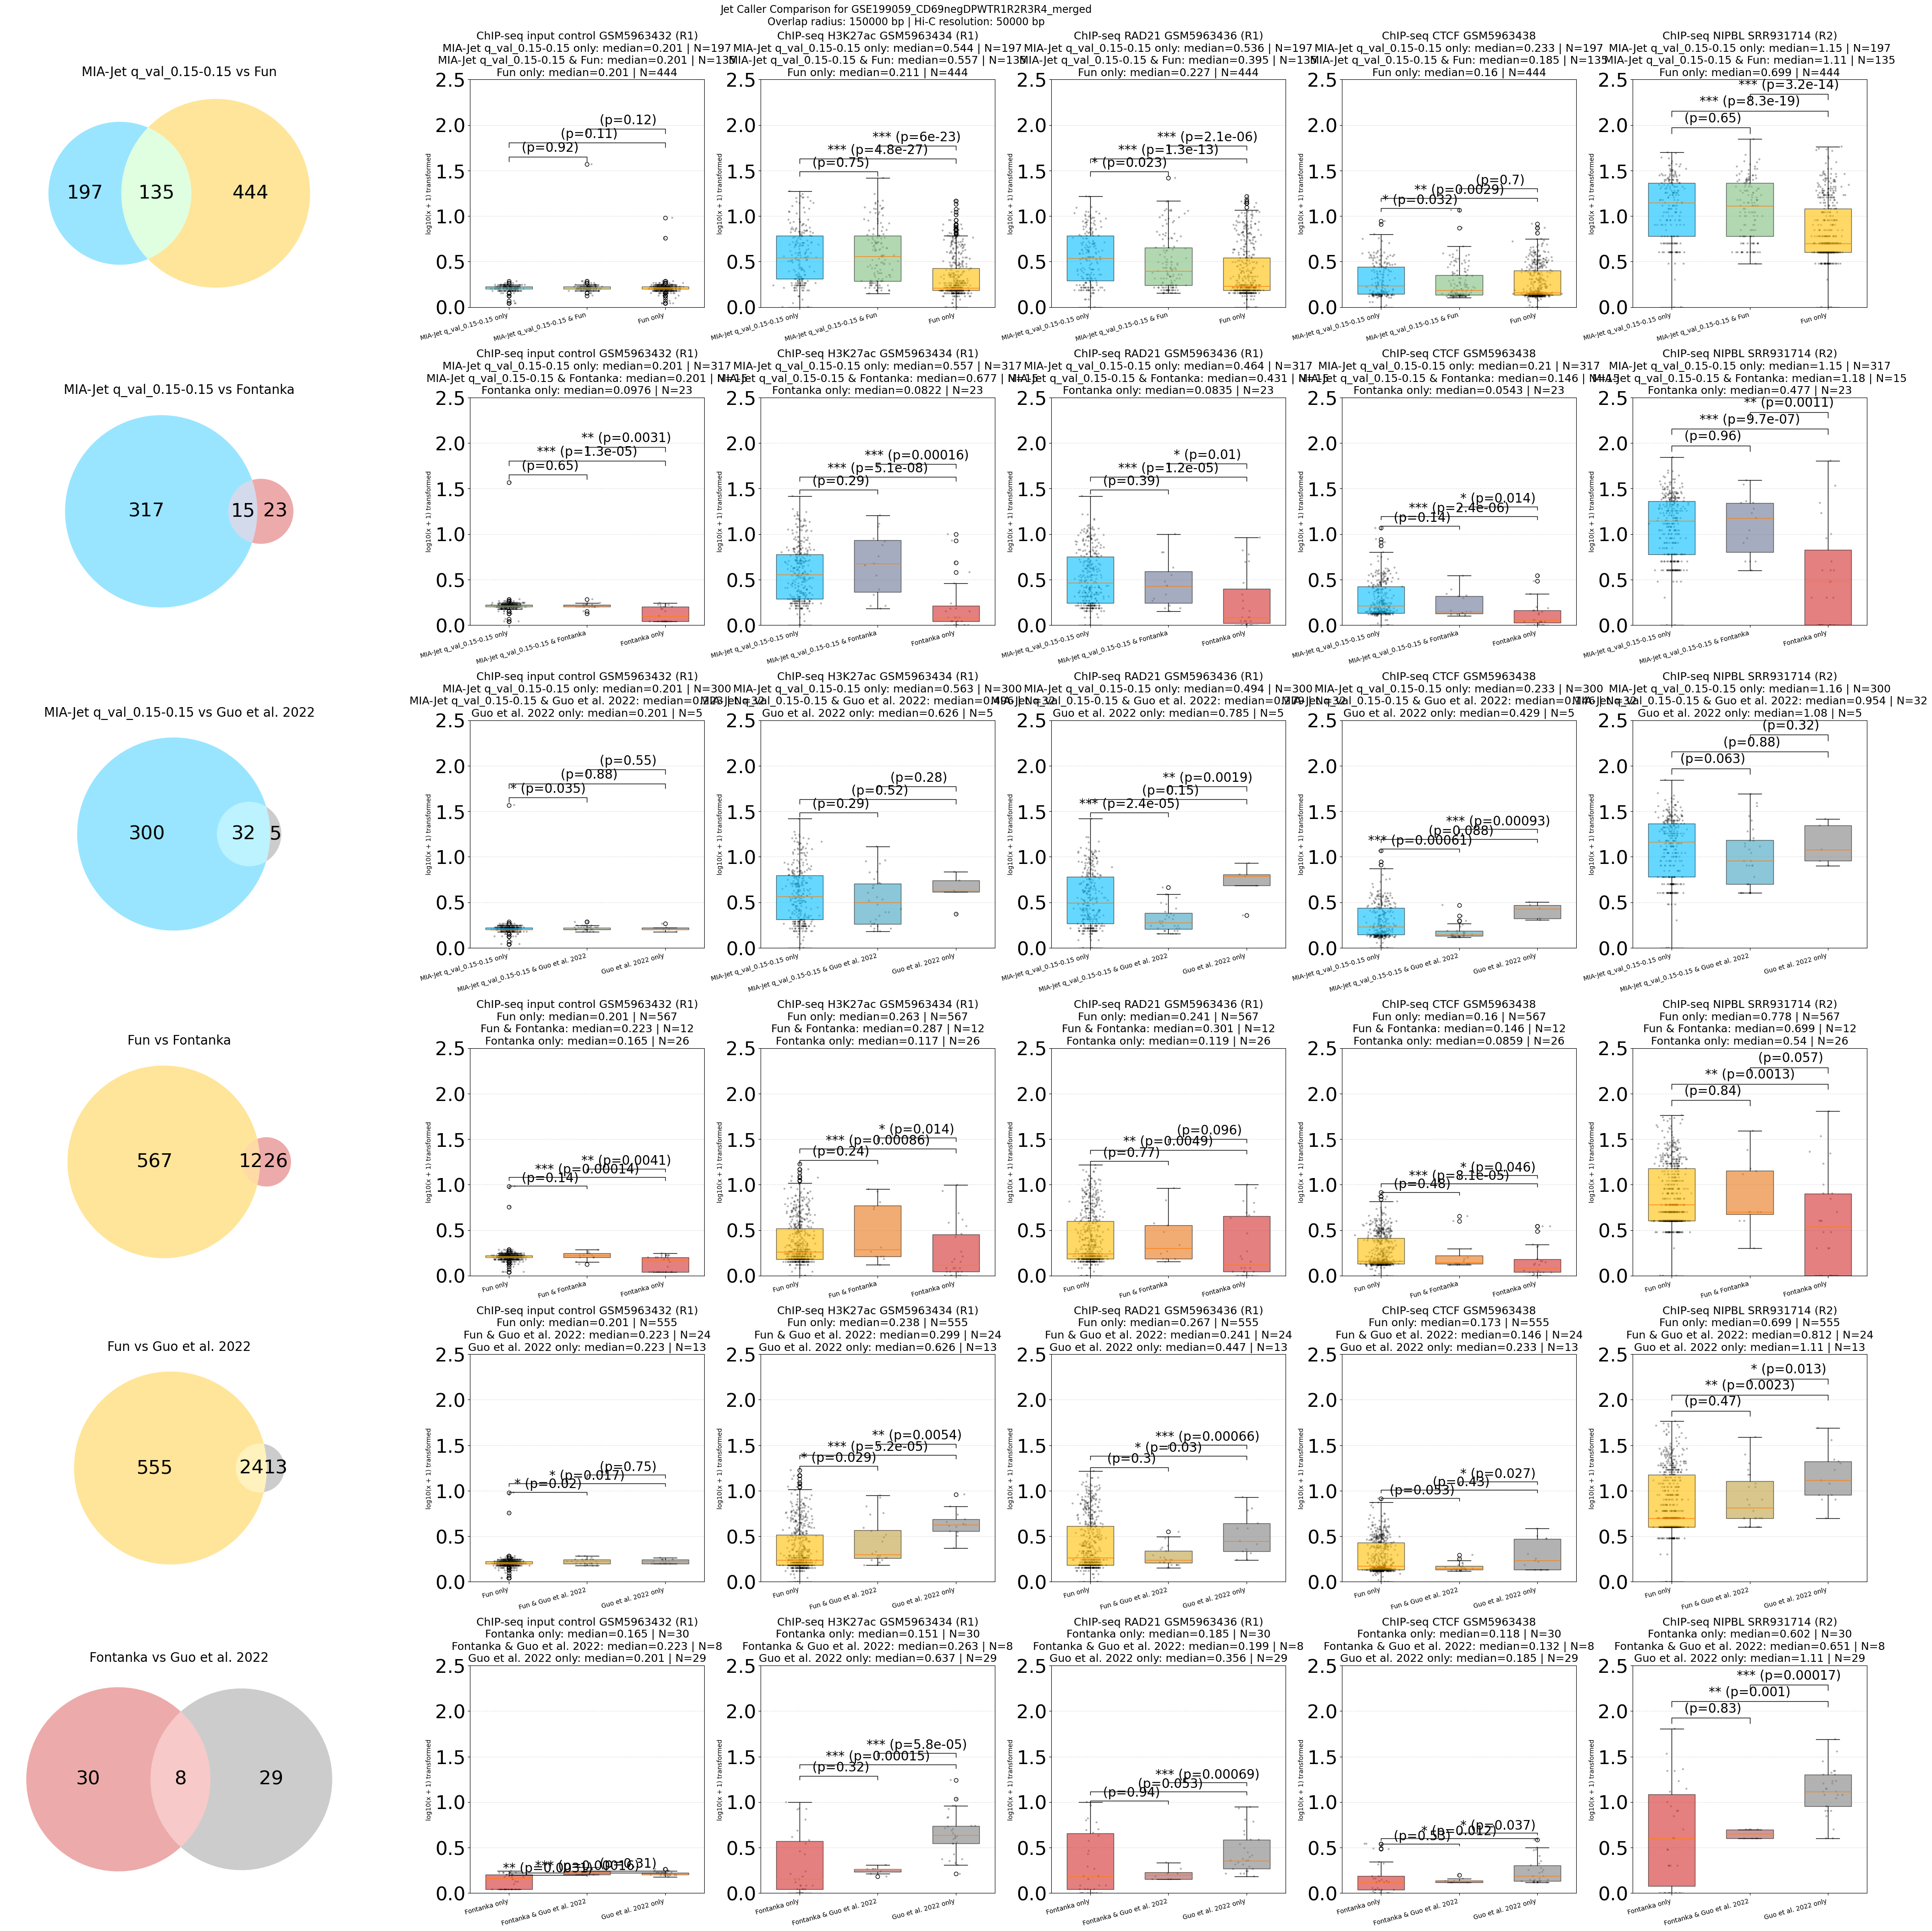

In [24]:
# colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

from matplotlib.colors import to_rgb
def mix(c1, c2, w=0.5):
    """ Mix colours """
    return tuple((1 - w)*np.array(to_rgb(c1)) + w*np.array(to_rgb(c2)))

pairs = list(itertools.combinations(names, 2))
num_pairs = len(pairs)
n_exp = len(chip_files)

fig, axes = plt.subplots(num_pairs, n_exp + 1, figsize=(7 * (n_exp + 1), 7 * num_pairs), layout='constrained', width_ratios=[2] + [1] * n_exp)

for row, (A, B) in enumerate(pairs):
    # 1) Venn diagram in col 0
    total_A = results.loc[A, A]
    total_B = results.loc[B, B]
    inter   = results.loc[A, B]
    only_A  = total_A - inter
    only_B  = total_B - inter

    titles = [f"{A} only", f"{A} & {B}", f"{B} only"]

    ax = axes[row, 0]
    v = venn2((int(only_A), int(only_B), int(inter)), 
                set_colors=(palette[A], palette[B]),
                set_labels=(f"", f""),
               ax=ax)

    for txt in v.set_labels:
        if txt is not None:
            txt.set_fontsize(30)

    for txt in v.subset_labels:
        if txt is not None:
            txt.set_fontsize(30)

    ax.set_title(f"{A} vs {B}", fontsize=20)

    row_boxes = boxplot_pairs[row]     

    # counts per category (for the titles below)
    counts = [int(only_A), int(inter), int(only_B)]

    # 2) one box‐axis per experiment
    for exp_idx in range(n_exp):
        ax = axes[row, exp_idx+1]

        # gather the 3 arrays (one per category) for this experiment
        data = [row_boxes[cat][exp_idx] for cat in range(3)]
        # drop NaNs
        clean = [np.array(d)[~np.isnan(d)] if len(d) != 0 else [] for d in data]
        clean = [np.clip(vals, 0, None) for vals in clean]  # clip negative values to zero
        clean = [np.log10(vals + 1) for vals in clean]  # log transform

        positions = np.arange(1, 4) # A, A&B, B 
        bp = ax.boxplot(clean, patch_artist=True,
                        positions=positions, widths=0.6)
        
        add_pairwise_sig(ax, positions, clean, fontsize=20, y_pad=0.1, pad_from_max=-0.12)

        # color by category
        cat_cols = [palette[A], mix(palette[A], palette[B]), palette[B]]
        for patch, col in zip(bp['boxes'], cat_cols):
            patch.set_facecolor(col)
            patch.set_alpha(0.6)

        # overplot jittered points
        for i, vals in enumerate(clean):
            x = np.full_like(vals, positions[i], dtype=float)
            x += np.random.normal(0, 0.08, size=len(vals))
            ax.scatter(x, vals, alpha=0.3, s=10, color='k', edgecolor='none')

        ax.set_xticks(positions)
        ax.set_xticklabels(titles, rotation=15, ha='right')
        ax.tick_params(axis='y', labelsize=30)

        title_boxstat = title_boxplot(chip_names[exp_idx], titles, clean)
        ax.set_title(title_boxstat, fontsize=17)

        ax.set_ylabel("log10(x + 1) transformed")
        ax.grid(axis='y', linestyle='--', alpha=0.4)

        ax.set_ylim(0, 2.5)

# overall title
fig.suptitle(
    f"Jet Caller Comparison for {data_name}\n"
    f"Overlap radius: {int(buffer_radius)} bp | Hi-C resolution: {resolution} bp",
    fontsize=16
)

plt.savefig(f"{save_path}/{data_name}_{resolution_miajet}_{result_type}_venn_diagram-box.png", dpi=400)

plt.show()